In [ ]:
import pandas as pd

df_2019 = pd.read_excel(
    "data-pengaduan-masyarakat-yang-disampaikan-melalui-aplikasi-crm-tahun-2019-komponen-data.xlsx",
    sheet_name="Data"
)
df_2020 = pd.read_excel(
    "data-rekapitulasi-laporan-cepat-respon-masyarakat-per-kelurahan-kota-administrasi-jakarta-barat-tahun-2020-komponen-data.xlsx",
    sheet_name="Data"
)

df = pd.concat(
    [df_2019[["kategori", "rincian_masalah"]], df_2020[["kategori", "rincian_masalah"]]],
    ignore_index=True
)
print("Total data gabungan:", len(df))

Total data gabungan: 16651


In [ ]:
import re

label_map = {
    "JALAN": "jalan_rusak",
    "TROTOAR": "jalan_rusak",
    "JEMBATAN PENYEBERANGAN ORANG (JPO) DAN/ATAU HALTE": "jalan_rusak",
    "SAMPAH": "kebersihan_dan_drainase",
    "BANJIR": "kebersihan_dan_drainase",
    "SALURAN AIR": "kebersihan_dan_drainase",
    "SALURAN AIR KALI/SUNGAI": "kebersihan_dan_drainase",
    "SALURAN AIR, KALI/SUNGAI": "kebersihan_dan_drainase",
    "TUTUP SALURAN": "kebersihan_dan_drainase",
    "PENCEMARAN LINGKUNGAN": "kebersihan_dan_drainase",
    "POHON": "taman_penataan_lingkungan",
    "TAMAN": "taman_penataan_lingkungan",
    "RUANG PUBLIK TERPADU RAMAH ANAK (RPTRA)": "taman_penataan_lingkungan",
    "TAMAN PEMAKAMAN UMUM": "taman_penataan_lingkungan",
    "JARINGAN LISTRIK": "utilitas_listrik_dan_pju",
}

df["label"] = df["kategori"].map(label_map)
df = df.dropna(subset=["label", "rincian_masalah"]).copy()

# Buang baris placeholder
placeholder = {'NULL"', "NULL", "KOSONG", "LAIN-LAIN:\nNULL", "LAIN-LAIN:", "LAIN-LAIN", ""}
df["rincian_masalah"] = df["rincian_masalah"].astype(str).str.strip()
df = df[~df["rincian_masalah"].isin(placeholder)].copy()

def bersihkan_teks(teks):
    teks = re.sub(r"^LAIN-LAIN:\s*", "", str(teks), flags=re.IGNORECASE)
    teks = teks.replace('"', "").lower()
    teks = re.sub(r"[^a-z0-9\s]", " ", teks)
    return re.sub(r"\s+", " ", teks).strip()

df["teks"] = (df["kategori"] + " " + df["rincian_masalah"]).apply(bersihkan_teks)
df = df[df["teks"].str.len() >= 3].reset_index(drop=True)

print("Jumlah data siap latih:", len(df))
print(df["label"].value_counts())

Jumlah data siap latih: 9705
label
kebersihan_dan_drainase      7831
jalan_rusak                  1123
taman_penataan_lingkungan     620
utilitas_listrik_dan_pju      131
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

classes = sorted(df["label"].unique().tolist())
label_to_idx = {nama: i for i, nama in enumerate(classes)}
df["y"] = df["label"].map(label_to_idx)

X_train, X_test, y_train, y_test = train_test_split(
    df["teks"].values,
    df["y"].values,
    test_size=0.20,
    stratify=df["y"].values,
    random_state=42
)
print(f"Data Train: {len(X_train)} | Data Test: {len(X_test)}")

Data Train: 7764 | Data Test: 1941


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_VOCAB = 5000
MAX_LEN = 30

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_pad = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN, padding="post")
X_test_pad = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=MAX_LEN, padding="post")

vocab_size = min(MAX_VOCAB, len(tokenizer.word_index) + 1)
print("Jumlah kosakata unik:", vocab_size)

Jumlah kosakata unik: 793


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

tf.random.set_seed(42)

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=MAX_LEN),
    LSTM(64),
    Dropout(0.3),
    Dense(len(classes), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=32
)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


219/219 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8752 - loss: 0.3826 - val_accuracy: 0.9215 - val_loss: 0.1697
Epoch 2/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.9167 - loss: 0.1885 - val_accuracy: 0.9215 - val_loss: 0.1686
Epoch 3/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9200 - loss: 0.1819 - val_accuracy: 0.9215 - val_loss: 0.1686
Epoch 4/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9230 - loss: 0.1720 - val_accuracy: 0.9755 - val_loss: 0.0977
Epoch 5/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.9821 - loss: 0.0643 - val_accuracy: 0.9871 - val_loss: 0.0382
Epoch 6/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9858 - loss: 0.0470 - val_accuracy: 0.9871 - val_loss: 0.0360
Epoch 7/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9070 - loss: 0.3754 - val_accuracy: 0.9228 - val_loss: 0.3019
Epoch 8/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.9226 - loss: 0.3139 - val_accuracy: 0.922

In [ ]:
import json
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

pred_probs = model.predict(X_test_pad)
y_pred = np.argmax(pred_probs, axis=1)

print(classification_report(y_test, y_pred, target_names=classes))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Simpan 3 artefak untuk di-download dari Colab ke folder CivicPulseApp
model.save("civicpulse_lstm.keras")

with open("tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

with open("label_classes.json", "w", encoding="utf-8") as f:
    json.dump({"classes": classes, "max_len": MAX_LEN}, f)

print("Selesai! Silakan download civicpulse_lstm.keras, tokenizer.json, dan label_classes.json.")

61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
                           precision    recall  f1-score   support

              jalan_rusak       1.00      1.00      1.00       225
  kebersihan_dan_drainase       0.91      1.00      0.95      1566
taman_penataan_lingkungan       0.00      0.00      0.00       124
 utilitas_listrik_dan_pju       0.00      0.00      0.00        26

                 accuracy                           0.92      1941
                macro avg       0.48      0.50      0.49      1941
             weighted avg       0.85      0.92      0.89      1941

Confusion Matrix:
 [[ 225    0    0    0]
 [   0 1566    0    0]
 [   0  124    0    0]
 [   0   26    0    0]]
Selesai! Silakan download civicpulse_lstm.keras, tokenizer.json, dan label_classes.json.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


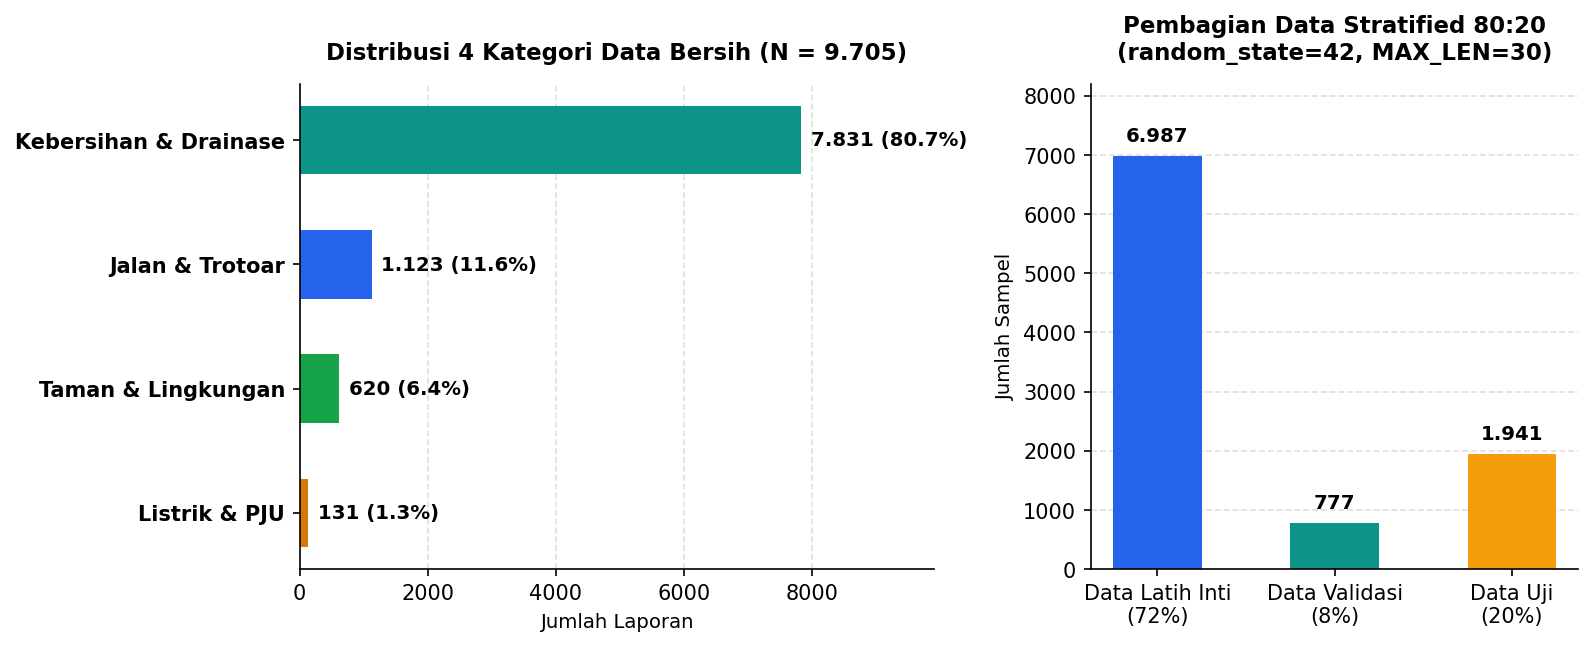

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data hasil pembersihan & stratified split 80:20 dari notebook CivicPulse
kategori_label = [
    "Kebersihan & Drainase",
    "Jalan & Trotoar",
    "Taman & Lingkungan",
    "Listrik & PJU"
]
jumlah_data = [7831, 1123, 620, 131]
persentase = [80.7, 11.6, 6.4, 1.3]
warna = ["#0D9488", "#2563EB", "#16A34A", "#D97706"]

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(11, 4.2), dpi=150,
    gridspec_kw={"width_ratios": [1.3, 1.0], "wspace": 0.28}
)

# Panel Kiri: Distribusi 4 Kategori Data Bersih (N = 9.705)
y_pos = np.arange(len(kategori_label))
bars = ax1.barh(y_pos, jumlah_data, color=warna, height=0.55)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(kategori_label, fontsize=10, fontweight="bold")
ax1.invert_yaxis()
ax1.set_xlim(0, 9900)
ax1.set_xlabel("Jumlah Laporan", fontsize=9.5)
ax1.set_title("Distribusi 4 Kategori Data Bersih (N = 9.705)", fontsize=11, fontweight="bold", pad=12)
ax1.grid(axis="x", linestyle="--", alpha=0.4)
ax1.set_axisbelow(True)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

for bar, c, p in zip(bars, jumlah_data, persentase):
    ax1.text(
        c + 150, bar.get_y() + bar.get_height() / 2,
        f"{c:,} ({p:.1f}%)".replace(",", "."),
        va="center", ha="left", fontsize=9.5, fontweight="bold"
    )

# Panel Kanan: Pembagian Data Stratified 80:20
split_label = ["Data Latih Inti\n(72%)", "Data Validasi\n(8%)", "Data Uji\n(20%)"]
split_jumlah = [6987, 777, 1941]
split_warna = ["#2563EB", "#0D9488", "#F59E0B"]

bars2 = ax2.bar(split_label, split_jumlah, color=split_warna, width=0.5)
ax2.set_ylim(0, 8200)
ax2.set_ylabel("Jumlah Sampel", fontsize=9.5)
ax2.set_title("Pembagian Data Stratified 80:20\n(random_state=42, MAX_LEN=30)", fontsize=11, fontweight="bold", pad=12)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.set_axisbelow(True)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

for bar, c in zip(bars2, split_jumlah):
    ax2.text(
        bar.get_x() + bar.get_width() / 2, c + 180,
        f"{c:,}".replace(",", "."),
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

plt.savefig("distribusi_dataset_civicpulse.png", dpi=300, bbox_inches="tight")
plt.show()

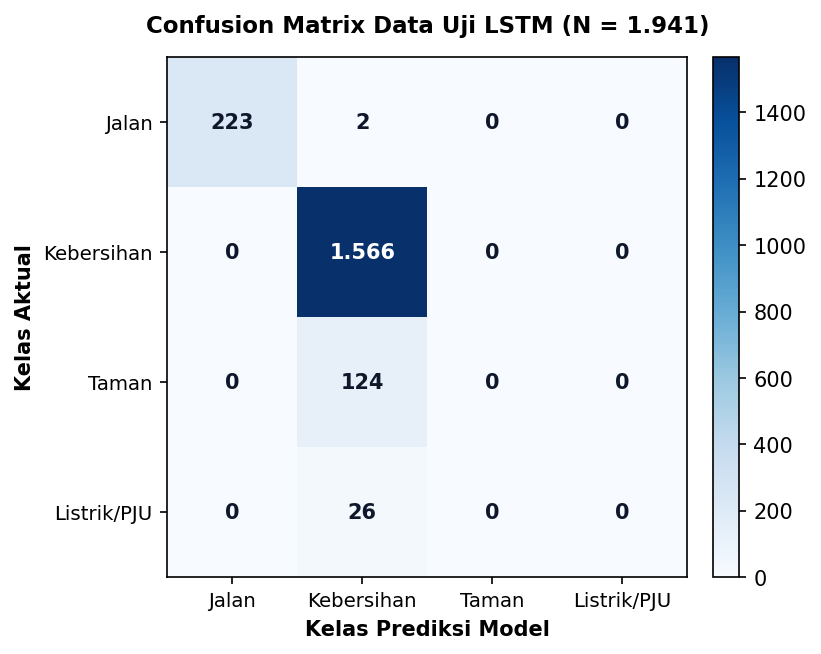

In [1]:
import matplotlib.pyplot as plt
import numpy as np

cm = np.array([
    [223,    2, 0, 0],
    [  0, 1566, 0, 0],
    [  0,  124, 0, 0],
    [  0,   26, 0, 0]
])
kelas_cm = ["Jalan", "Kebersihan", "Taman", "Listrik/PJU"]

fig, ax = plt.subplots(figsize=(5.5, 4.5), dpi=150)
im = ax.imshow(cm, cmap="Blues")
ax.set_title("Confusion Matrix Data Uji LSTM (N = 1.941)", fontsize=11, fontweight="bold", pad=12)
ax.set_xticks(np.arange(4))
ax.set_yticks(np.arange(4))
ax.set_xticklabels(kelas_cm, fontsize=9.5)
ax.set_yticklabels(kelas_cm, fontsize=9.5)
ax.set_xlabel("Kelas Prediksi Model", fontsize=10, fontweight="bold")
ax.set_ylabel("Kelas Aktual", fontsize=10, fontweight="bold")

for i in range(4):
    for j in range(4):
        val = cm[i, j]
        ax.text(
            j, i, f"{val:,}".replace(",", "."),
            ha="center", va="center",
            color="white" if val > 700 else "#0F172A",
            fontsize=10, fontweight="bold"
        )

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.savefig("confusion_matrix_civicpulse.png", dpi=300, bbox_inches="tight")
plt.show()